In [1]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/CE200292_TranThanhGiaKhang_Lab1
!ls

Mounted at /content/drive
/content/drive/MyDrive/CE200292_TranThanhGiaKhang_Lab1
config.yaml  RAF-DB.zip  report_assets	requirements.txt  tools
notebooks    README.md	 report.pdf	src		  weights


In [3]:
!unzip -q /content/drive/MyDrive/RAF-DB.zip -d /content/raf
!ls /content/raf
!ls /content/raf/DATASET/train/1 | head -3

DATASET  test_labels.csv  train_labels.csv
train_00006_aligned.jpg
train_00010_aligned.jpg
train_00012_aligned.jpg


Đã lưu raf_check.png. Mở ra xem: hàng '4 -> happy' phải toàn mặt cười, '1 -> surprise' phải ngạc nhiên...


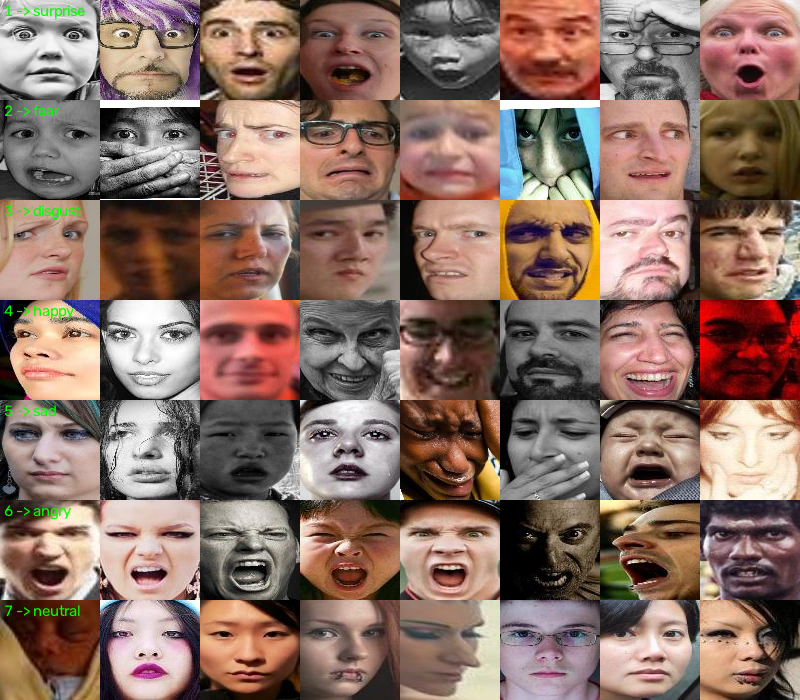

In [4]:
!rm -f raf_check.png
!python tools/finetune_raf.py --check-labels --raf-dir /content/raf/DATASET
from IPython.display import Image, display
display(Image('raf_check.png'))

In [5]:
!pip install -q kagglehub
import kagglehub
FER = kagglehub.dataset_download("msambare/fer2013")
print(FER)
!ls {FER}

Using Colab cache for faster access to the 'fer2013' dataset.
/kaggle/input/fer2013
test  train


In [7]:
!python tools/finetune_raf.py --fer-dir {FER} --raf-dir /content/raf/DATASET --init weights/transfer.pt --out weights/transfer_raf.pt --epochs 10

Đọc dữ liệu...

lớp         FER train  RAF train  FER test  RAF test   (ghi vào report)
angry            3995        705       958       162
disgust           436        717       111       160
fear             4097        281      1024        74
happy            7215       4772      1774      1185
neutral          4965       2524      1233       680
sad              4830       1982      1247       478
surprise         3171       1290       831       329
tổng            28709      12271      7178      3068

class weight: {'angry': np.float32(1.25), 'disgust': np.float32(5.08), 'fear': np.float32(1.34), 'happy': np.float32(0.49), 'neutral': np.float32(0.78), 'sad': np.float32(0.86), 'surprise': np.float32(1.31)}
[TRƯỚC fine-tune] FER test: acc 0.6668 F1 0.6524 | RAF test: acc 0.5883 F1 0.4033
epoch  1  train loss 1.0176  val acc 0.6862  val F1 0.6330  <- lưu
epoch  2  train loss 0.9032  val acc 0.7152  val F1 0.6697  <- lưu
epoch  3  train loss 0.8655  val acc 0.7023  val F1 0.6529
epoc

In [9]:
!python tools/finetune_raf.py --fer-dir {FER} --raf-dir /content/raf/DATASET --init weights/cnn.pt --out weights/cnn_raf.pt --min-fer-acc 0.60 --epochs 10

Đọc dữ liệu...

lớp         FER train  RAF train  FER test  RAF test   (ghi vào report)
angry            3995        705       958       162
disgust           436        717       111       160
fear             4097        281      1024        74
happy            7215       4772      1774      1185
neutral          4965       2524      1233       680
sad              4830       1982      1247       478
surprise         3171       1290       831       329
tổng            28709      12271      7178      3068

class weight: {'angry': np.float32(1.25), 'disgust': np.float32(5.08), 'fear': np.float32(1.34), 'happy': np.float32(0.49), 'neutral': np.float32(0.78), 'sad': np.float32(0.86), 'surprise': np.float32(1.31)}
[TRƯỚC fine-tune] FER test: acc 0.6450 F1 0.6081 | RAF test: acc 0.6307 F1 0.4656
epoch  1  train loss 1.2358  val acc 0.6484  val F1 0.5895  <- lưu
epoch  2  train loss 1.1781  val acc 0.6430  val F1 0.5794
epoch  3  train loss 1.1295  val acc 0.6408  val F1 0.5800
epoch  4  tr